# Data Visualization with Matplotlib and Seaborn
### Superstore Sales: Line, Bar, Histogram, Pie, Box, Scatter and Heatmap


clean.csv : the clean Superstore data that we saved at the end of Unit 3 (after removing duplicates, fixing text, wrong values and missing values)

**Chart size:** every chart in this file uses figsize=(5,3). A few places are bigger: the side by side charts (subplots), the dashboard, the pair plot (each small chart still gets about 5 x 3 or less) and the homework heatmap of 17 sub-categories (it needs more height to be readable).

Topics of Unit 5 covered here (Experiments 8 and 9 of the lab)

1. Setup and loading the data
2. Why we visualize data, principles of a good chart
3. Matplotlib basics
4. Line chart
5. Bar chart (simple, horizontal, stacked, grouped)
6. Bad chart: the cut axis
7. Which chart to use?
8. Histogram
9. Pie chart and donut chart
10. Box plot
11. Scatter plot
12. Heatmap
13. Seaborn: charts in one line (line, bar, histogram, box, violin, scatter, heatmap, pair plot)
14. Subplots: a mini dashboard
15. Customizing plots (titles, labels, legend, colors, annotation, saving)
16. Cheat sheet, common mistakes, recap and homework

# LOADING THE FILE

In [171]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [172]:
dfc=pd.read_csv("clean.csv")
dfc.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Ship Days,Discount %
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,54.900,2,0.00,41.9136,2016,November,3,0
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.940,3,0.00,219.5820,2016,November,3,0
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,0.00,6.8714,2016,June,4,0
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,54.900,5,0.45,-383.0310,2015,October,7,45
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.368,2,0.20,2.5164,2015,October,7,20


In [173]:
print(dfc.shape)
dfc.info()

(9994, 24)
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Region         9994 non-null   str    
 12  Product ID     9994 non-null   str    
 13  Category       9994 non-null   str    
 14  Sub-Category   9994 non-null   str    
 15  Product Name   9994 non-null   str    
 16  Sales          9994 non-null   float64
 17  Quantity       9994 non-null   int64  
 18  Discount

In [174]:
dfc.isna().sum().sum()      # 0 means no missing values, this is the clean file

np.int64(0)

Dates are saved as text in a csv file, so we convert them again. `Year`, `Month` and `Ship Days` are already in `clean.csv`. We add only `MonthNo` (1 to 12), because month names (Apr, Aug, Dec...) sort in alphabetical order and not in calendar order.

In [175]:
dfc["Order Date"]=pd.to_datetime(dfc["Order Date"])
dfc["Ship Date"]=pd.to_datetime(dfc["Ship Date"])
dfc["MonthNo"]=dfc["Order Date"].dt.month
dfc[["Order Date","Year","Month","MonthNo","Ship Days"]].head()

,Order Date,Year,Month,MonthNo,Ship Days
0,2016-11-08,2016,November,11,3
1,2016-11-08,2016,November,11,3
2,2016-06-12,2016,June,6,4
3,2015-10-11,2015,October,10,7
4,2015-10-11,2015,October,10,7


# 2. Why We Visualize Data

Three reasons

* Find patterns and outliers quickly
* Check data quality
* Explain the result to people who do not read tables

Same four numbers, first as a table and then as a chart. Which one is faster to read?

In [176]:
yearly=dfc.groupby("Year")["Sales"].sum()
yearly

Year
2014    463395.7799
2015    453069.8395
2016    586838.4132
2017    709241.3082
Name: Sales, dtype: float64

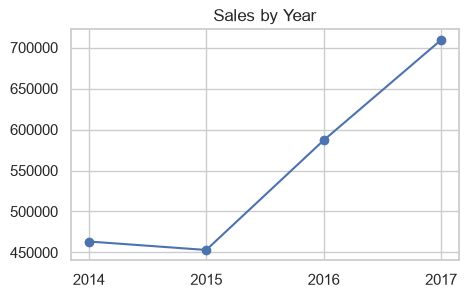

In [177]:
plt.figure(figsize=(5,3))
plt.plot(yearly.index,yearly.values,marker="o")
plt.xticks(yearly.index)
plt.title("Sales by Year")
plt.show()

The chart shows the trend at a glance: sales went down a little in 2015 and then went up every year.

### Choose the chart by the type of data

| Data | Chart |
|---|---|
| One category column | Bar chart |
| One number column | Histogram or Box plot |
| Number over time | Line chart |
| Two number columns | Scatter plot |
| Many number columns | Heatmap |
| Share of a whole | Pie chart (5 slices or less) |

### Principles of a good chart

| Do | Avoid |
|---|---|
| Add a title, axis labels and units | Extra decoration and 3D charts |
| Start bar charts at zero | Pie charts with many slices |
| Use color with a meaning | Cutting the axis to exaggerate a gap |
| Use colors that color-blind people can read | The wrong chart for the data |

A chart must be honest and easy to read.

# 3. Matplotlib Basics

* Figure = the whole picture
* Axes = the place where the data is drawn
* `figsize=(width,height)` sets the size in inches
* `plt.savefig()` must come before `plt.show()`, otherwise the saved image is blank
* `plt.subplots()` gives many charts in one figure

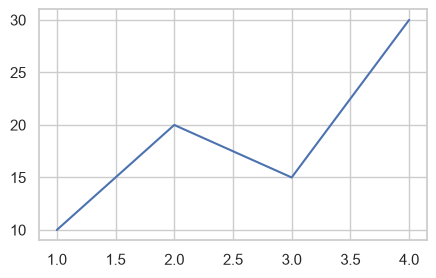

In [178]:
x=[1,2,3,4]
y=[10,20,15,30]

plt.figure(figsize=(5,3))     # width, height
plt.plot(x,y)                 # draw a line
plt.savefig("first.png",dpi=300)    # save image, before show
plt.show()                    # show chart

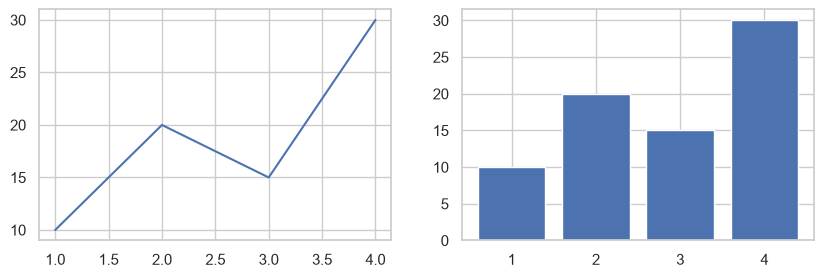

In [179]:
# many charts in one figure : 1 row, 2 columns, so the width is 2 x 5 = 10
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].plot(x,y)
axes[1].bar(x,y)
plt.show()

# 4. Line Chart: Trend Over Time

Use a line chart when the x axis is time (day, month, year). The points must be in time order, so sort or group by the date first.

`plt.plot(x,y)` draws the line, `marker="o"` puts a dot on every point.

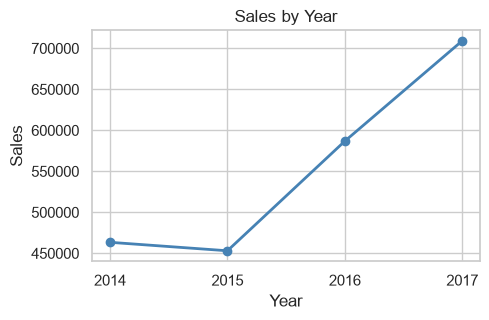

In [180]:
yearly=dfc.groupby("Year")["Sales"].sum()

plt.figure(figsize=(5,3))
plt.plot(yearly.index,yearly.values,marker="o",linewidth=2,color="steelblue")
plt.xticks(yearly.index)        # show only whole years on the x axis
plt.title("Sales by Year")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.show()

Sales dipped in 2015, then rose every year and reached the highest value in 2017.

### Your Turn: Monthly Sales

1. Plot monthly Sales for 2017
2. Add 2016 as a second line, with a legend
3. Add title, labels and markers
4. Which month is the lowest?

Careful: `dfc["Month"]` has names, so we use `MonthNo` to get the correct order.

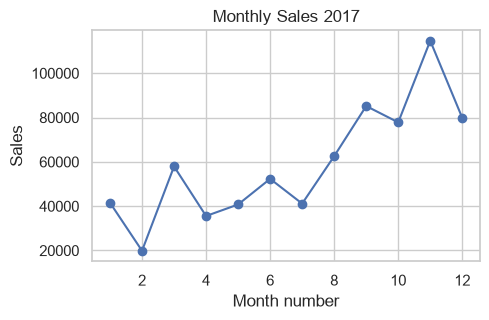

In [181]:
# Task 1 : 2017 only
d17=dfc[dfc["Year"]==2017]
m17=d17.groupby("MonthNo")["Sales"].sum()

plt.figure(figsize=(5,3))
plt.plot(m17.index,m17.values,marker="o")
plt.title("Monthly Sales 2017")
plt.xlabel("Month number")
plt.ylabel("Sales")
plt.show()

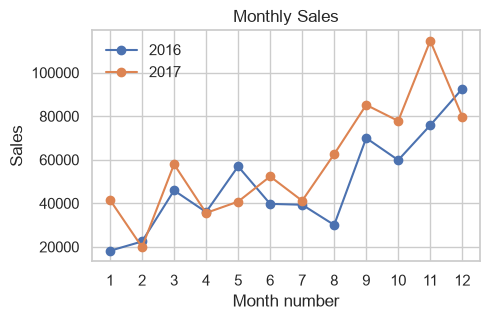

In [182]:
# Task 2 and 3 : two years in one chart
plt.figure(figsize=(5,3))
for year in [2016,2017]:
    d=dfc[dfc["Year"]==year]
    m=d.groupby("MonthNo")["Sales"].sum()
    plt.plot(m.index,m.values,marker="o",label=str(year))

plt.legend()      # tells which line is which
plt.title("Monthly Sales")
plt.xlabel("Month number")
plt.ylabel("Sales")
plt.xticks(range(1,13))
plt.show()

In [183]:
# Task 4 : lowest month
for year in [2016,2017]:
    m=dfc[dfc["Year"]==year].groupby("MonthNo")["Sales"].sum()
    print(year,"lowest month number :",m.idxmin(),"sales :",round(m.min()))

2016 lowest month number : 1 sales : 18188
2017 lowest month number : 2 sales : 19876


# 5. Bar Chart: Compare Categories

Use a bar chart to compare a number across categories. A bar chart must start at zero, and sorted bars are easier to compare.

* `plt.bar()` vertical bars
* `plt.barh()` horizontal bars (good for long names)
* `plt.bar_label()` writes the value on every bar

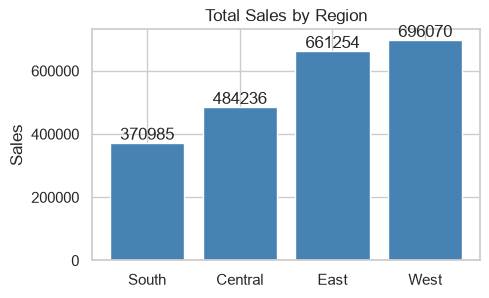

In [184]:
rs=dfc.groupby("Region")["Sales"].sum()
rs=rs.sort_values()       # small to large

plt.figure(figsize=(5,3))
bars=plt.bar(rs.index,rs.values,color="steelblue")
plt.bar_label(bars,fmt="%.0f")      # numbers on bars
plt.title("Total Sales by Region")
plt.ylabel("Sales")
plt.show()

West is the highest and South is the lowest.

### Horizontal bars

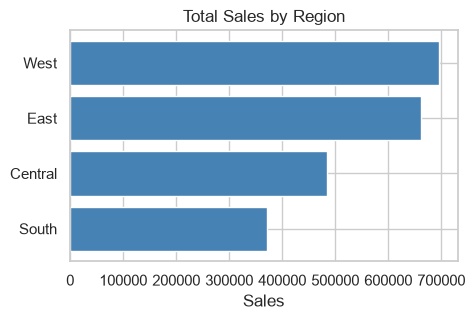

In [185]:
plt.figure(figsize=(5,3))
plt.barh(rs.index,rs.values,color="steelblue")
plt.title("Total Sales by Region")
plt.xlabel("Sales")
plt.show()

### Stacked bars

A stacked bar shows the total and also its parts. We use Sales here, because Profit can be negative and negative parts do not stack properly.

`bottom` tells where the next part starts. After every part we add its height to `bottom`.

In [186]:
t=pd.pivot_table(dfc,index="Region",columns="Category",values="Sales",aggfunc="sum")
t

Category,Furniture,Office Supplies,Technology
Region,,,
Central,156934.3308,165111.955,162189.964
East,204544.8280,204996.035,251713.377
South,103738.5225,124889.089,142356.960
West,242855.1975,218024.104,235190.978


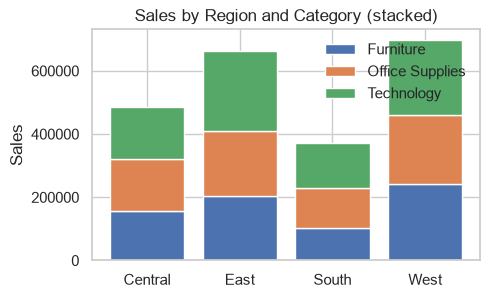

In [187]:
bottom=np.zeros(len(t))         # start at zero
plt.figure(figsize=(5,3))
for c in t.columns:
    plt.bar(t.index,t[c],bottom=bottom,label=c)
    bottom=bottom+t[c].values   # next part starts on top of this one
plt.legend()
plt.title("Sales by Region and Category (stacked)")
plt.ylabel("Sales")
plt.show()

### Grouped bars

Bars of each category stand side by side. Here we use Profit, so a loss goes below zero.

* `x` has one place for every region
* `w` is the width of one bar
* `x + i*w` moves every category a little to the right

In [188]:
t=pd.pivot_table(dfc,index="Region",columns="Category",values="Profit",aggfunc="sum")
t

Category,Furniture,Office Supplies,Technology
Region,,,
Central,-3100.3202,11023.4871,31841.7783
East,1512.3237,39832.2028,44574.0046
South,5394.8089,19475.9273,18444.3588
West,10423.7179,50459.4780,35291.3674


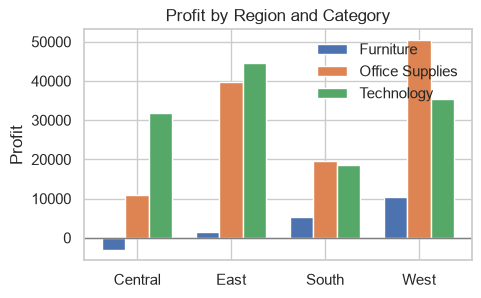

In [189]:
x=np.arange(len(t.index))     # one place per region
w=0.25                        # width of one bar

plt.figure(figsize=(5,3))
for i,c in enumerate(t.columns):
    plt.bar(x+i*w,t[c],w,label=c)

plt.xticks(x+w,t.index)       # region names in the middle of the 3 bars
plt.axhline(0,color="gray",linewidth=1)
plt.legend()
plt.title("Profit by Region and Category")
plt.ylabel("Profit")
plt.show()

In [190]:
tt=t.stack()
print(tt[tt<0])     # the cells where profit is negative (a loss)

Region   Category 
Central  Furniture   -3100.3202
dtype: float64


### Your Turn: Average Profit by Category

Build a bar chart of the average Profit of each Category. Sort it and show the values on the bars.

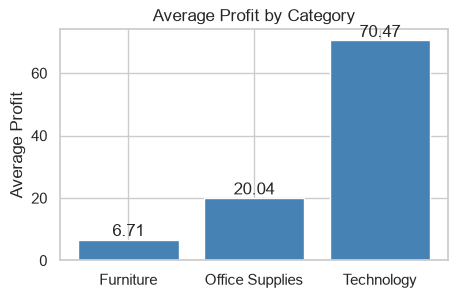

In [191]:
ap=dfc.groupby("Category")["Profit"].mean()
ap=ap.sort_values()

plt.figure(figsize=(5,3))
bars=plt.bar(ap.index,ap.values,color="steelblue")
plt.bar_label(bars,fmt="%.2f")
plt.title("Average Profit by Category")
plt.ylabel("Average Profit")
plt.show()

# 6. Bad Chart: The Cut Axis

Same data, two bar charts. In the second one the y axis starts at 350000 and not at zero.

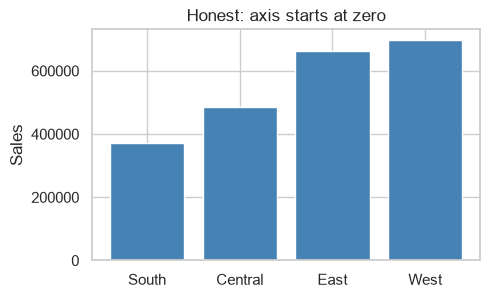

In [192]:
rs=dfc.groupby("Region")["Sales"].sum().sort_values()

plt.figure(figsize=(5,3))
plt.bar(rs.index,rs.values,color="steelblue")
plt.title("Honest: axis starts at zero")
plt.ylabel("Sales")
plt.show()

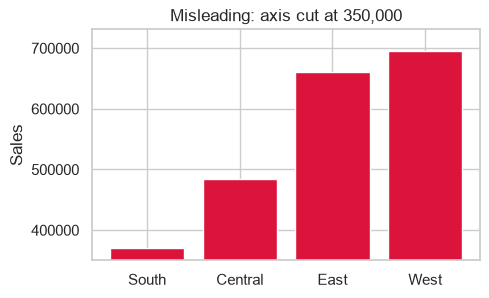

In [193]:
cut=int(rs.min()*0.95/10000)*10000      # a round number just below the smallest bar
plt.figure(figsize=(5,3))
plt.bar(rs.index,rs.values,color="crimson")
plt.ylim(cut,rs.max()*1.05)             # axis is cut, South looks tiny
plt.title(f"Misleading: axis cut at {cut:,}")
plt.ylabel("Sales")
plt.show()

In [194]:
print("West is only",round(rs["West"]/rs["South"],1),"times South")

West is only 1.9 times South


The cut axis makes South look very small. In the real data West is only about 1.9 times South. A bar chart always starts at zero.

# 7. Activity: Which Chart?

Q1. Orders in each Segment

Q2. Total sales for each month

Q3. How Quantity values are spread

Q4. Do bigger sales give bigger profit?

Q5. Share of orders by Ship Mode

Q6. Spread of Profit across Categories

Answers

Q1. Bar chart

Q2. Line chart

Q3. Histogram

Q4. Scatter plot

Q5. Pie or bar chart

Q6. Box plot

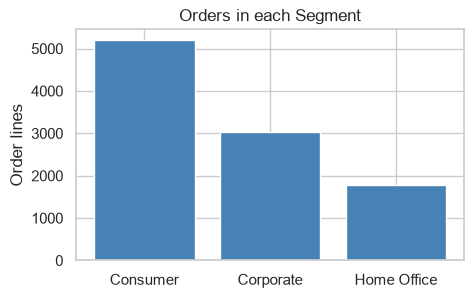

In [195]:
# Q1 as a quick check : orders in each Segment
sg=dfc["Segment"].value_counts()
plt.figure(figsize=(5,3))
plt.bar(sg.index,sg.values,color="steelblue")
plt.title("Orders in each Segment")
plt.ylabel("Order lines")
plt.show()

# 8. Histogram: See the Spread

A histogram takes one number column and cuts it into bins. The height of a bar is how many rows fall in that bin.

* `bins` is the number of bars, or the list of bin edges
* `edgecolor="white"` puts a white line between the bars

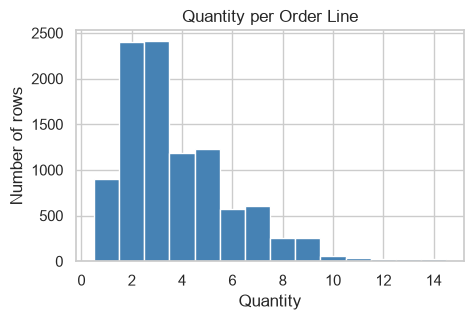

In [196]:
plt.figure(figsize=(5,3))
plt.hist(dfc["Quantity"],
         bins=np.arange(0.5,15.5,1),      # one bar per value
         color="steelblue",edgecolor="white")
plt.title("Quantity per Order Line")
plt.xlabel("Quantity")
plt.ylabel("Number of rows")
plt.show()

In [197]:
dfc["Quantity"].value_counts().sort_index()     # the same counts as a table

Quantity
1      899
2     2402
3     2409
4     1191
5     1230
6      572
7      606
8      257
9      258
10      57
11      34
12      23
13      27
14      29
Name: count, dtype: int64

Most rows buy 2 or 3 items. Very few rows buy 10 or more.

### Skewed data

Sales has a few very big values, so the chart is stretched to the right. We take Sales up to 500 only for display. The dashed line is the mean and the solid line is the median.

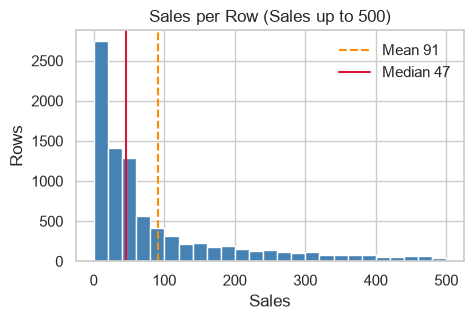

In [198]:
s=dfc.loc[dfc["Sales"]<=500,"Sales"]

plt.figure(figsize=(5,3))
plt.hist(s,bins=25,color="steelblue",edgecolor="white")
plt.axvline(s.mean(),color="darkorange",linestyle="--",label=f"Mean {s.mean():.0f}")
plt.axvline(s.median(),color="crimson",label=f"Median {s.median():.0f}")
plt.legend()
plt.title("Sales per Row (Sales up to 500)")
plt.xlabel("Sales")
plt.ylabel("Rows")
plt.show()

In [199]:
print("Rows with Sales up to 500 :",round(len(s)/len(dfc)*100),"%")

Rows with Sales up to 500 : 89 %


Right-skewed: a few big sales pull the mean above the median. The mean is not a good "typical" value here, the median is better.

### Why bins matter

Same data, three pictures.

* Too few bins: the shape is hidden
* Too many bins: noise and gaps
* Start with 20 to 30 bins, then adjust, and write the bin count in the report

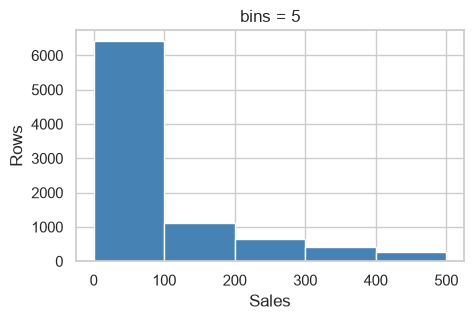

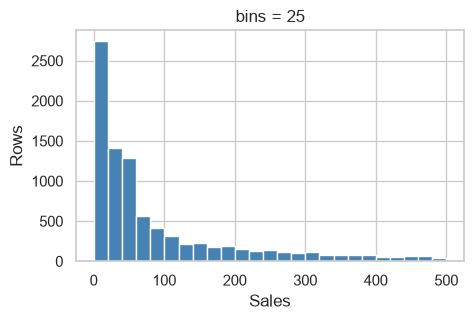

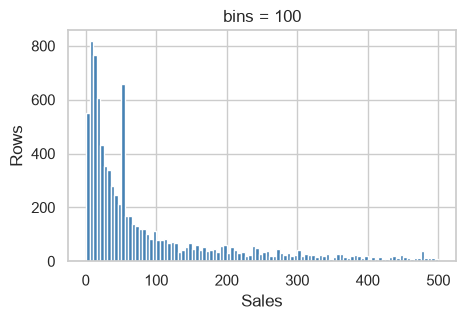

In [200]:
for b in [5,25,100]:
    plt.figure(figsize=(5,3))
    plt.hist(s,bins=b,color="steelblue")
    plt.title(f"bins = {b}")
    plt.xlabel("Sales")
    plt.ylabel("Rows")
    plt.show()

### Your Turn: Days to Ship

1. Plot a histogram of Ship Days
2. One bar for each whole day (0 to 7)
3. Add a dashed mean line and a legend
4. Which number of days is most common?

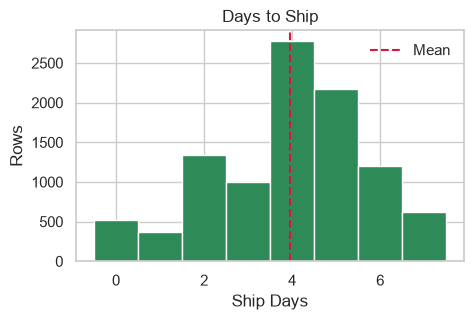

In [201]:
plt.figure(figsize=(5,3))
plt.hist(dfc["Ship Days"],
         bins=np.arange(-0.5,8.5,1),      # one bar for each day 0 to 7
         color="seagreen",edgecolor="white")
plt.axvline(dfc["Ship Days"].mean(),color="crimson",linestyle="--",label="Mean")
plt.legend()
plt.title("Days to Ship")
plt.xlabel("Ship Days")
plt.ylabel("Rows")
plt.show()

In [202]:
print("Mean ship days :",round(dfc["Ship Days"].mean(),2))
print("Most common ship days :",dfc["Ship Days"].value_counts().idxmax())

Mean ship days : 3.96
Most common ship days : 4


# 9. Pie Chart: Share of a Whole

A pie chart shows how one whole is divided into parts.

* `autopct="%1.1f%%"` writes the percentage on every slice
* `startangle=90` starts the first slice at the top
* `explode` pulls one slice out

Pie rules: parts of one whole and 5 slices or less. Otherwise use a bar chart.

In [203]:
cs=dfc.groupby("Category")["Sales"].sum()
cs

Category
Furniture          708072.8788
Office Supplies    713021.1830
Technology         791451.2790
Name: Sales, dtype: float64

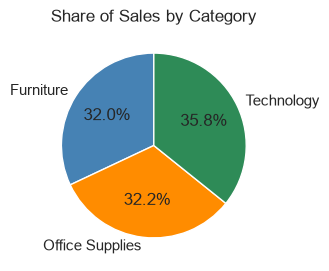

In [204]:
plt.figure(figsize=(5,3))
plt.pie(cs.values,labels=cs.index,autopct="%1.1f%%",startangle=90,
        colors=["steelblue","darkorange","seagreen"])
plt.title("Share of Sales by Category")
plt.show()

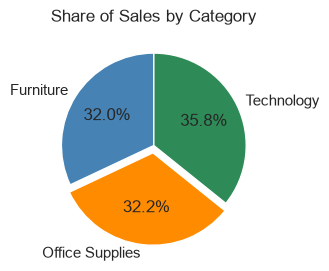

In [205]:
# pull one slice out : explode has one number for every slice
plt.figure(figsize=(5,3))
plt.pie(cs.values,labels=cs.index,autopct="%1.1f%%",startangle=90,
        colors=["steelblue","darkorange","seagreen"],
        explode=[0,0.08,0])
plt.title("Share of Sales by Category")
plt.show()

The three slices look almost equal. A bar chart would show the small gap between the categories better.

### Donut chart

A donut is a pie with a hole. `wedgeprops={"width":0.45}` makes the ring, and `plt.text()` writes in the middle.

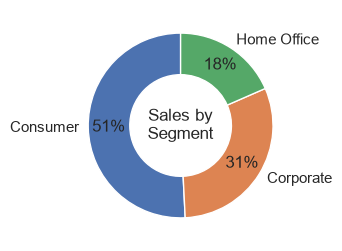

In [206]:
sg=dfc.groupby("Segment")["Sales"].sum()

plt.figure(figsize=(5,3))
plt.pie(sg.values,labels=sg.index,autopct="%1.0f%%",startangle=90,
        pctdistance=0.78,
        wedgeprops={"width":0.45,"edgecolor":"white"})
plt.text(0,0,"Sales by\nSegment",ha="center",va="center")
plt.show()

Consumer brings about half of all sales.

# 10. Box Plot: Read the Box

A box plot shows the spread of a number column using 5 values.

* The box is the middle 50% of rows, from Q1 to Q3. The line inside is the median.
* The whiskers go to the smallest and largest value that is not an outlier.
* Dots beyond the whiskers are outliers: above `Q3 + 1.5 x IQR` or below `Q1 - 1.5 x IQR`.

0.25    2.0
0.50    3.0
0.75    5.0
Name: Quantity, dtype: float64


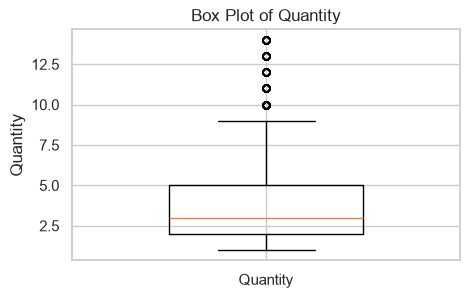

In [207]:
q=dfc["Quantity"]
print(q.quantile([0.25,0.5,0.75]))     # Q1, median, Q3

plt.figure(figsize=(5,3))
plt.boxplot(q,widths=0.5,flierprops={"markersize":5})
plt.xticks([1],["Quantity"])
plt.title("Box Plot of Quantity")
plt.ylabel("Quantity")
plt.show()

In [208]:
q1=q.quantile(0.25)
q3=q.quantile(0.75)
iqr=q3-q1
print("Upper fence :",q3+1.5*iqr)     # dots above this are outliers

Upper fence : 9.5


Box = middle 50% of rows: Q1 = 2, median = 3, Q3 = 5. The whisker reaches 9, and the dots above 9.5 are outliers.

### Compare groups

Many boxes in one chart. Left: with outliers. Right chart: outliers hidden with `showfliers=False`. If we hide the dots we must say it in the title.

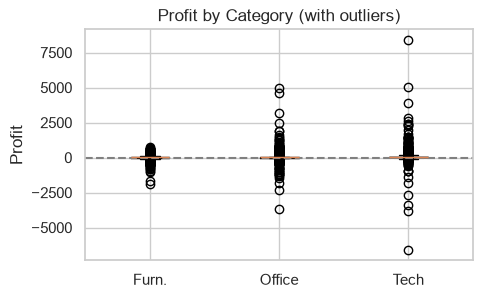

In [209]:
cats=["Furniture","Office Supplies","Technology"]
data=[dfc.loc[dfc["Category"]==c,"Profit"] for c in cats]     # list of 3 series, one for each box

plt.figure(figsize=(5,3))
plt.boxplot(data)
plt.xticks([1,2,3],["Furn.","Office","Tech"])
plt.axhline(0,color="gray",linestyle="--")
plt.title("Profit by Category (with outliers)")
plt.ylabel("Profit")
plt.show()

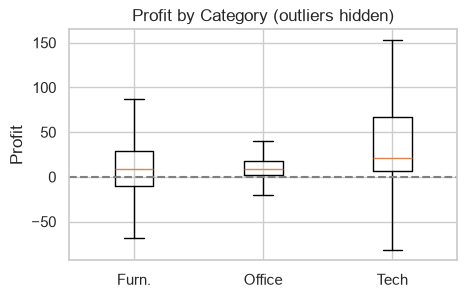

In [210]:
plt.figure(figsize=(5,3))
plt.boxplot(data,showfliers=False)
plt.xticks([1,2,3],["Furn.","Office","Tech"])
plt.axhline(0,color="gray",linestyle="--")
plt.title("Profit by Category (outliers hidden)")
plt.ylabel("Profit")
plt.show()

In [211]:
print(dfc.groupby("Category")["Profit"].median())

Category
Furniture           8.7372
Office Supplies     8.3892
Technology         20.7675
Name: Profit, dtype: float64


* Higher line = higher typical profit
* Taller box = more spread
* Technology has the highest median profit and the widest box

### Your Turn: Ship Days by Ship Mode

1. Box plot of Ship Days for each Ship Mode
2. Order: Same Day to Standard Class
3. Add title and y axis label
4. Which mode is slowest and most variable?

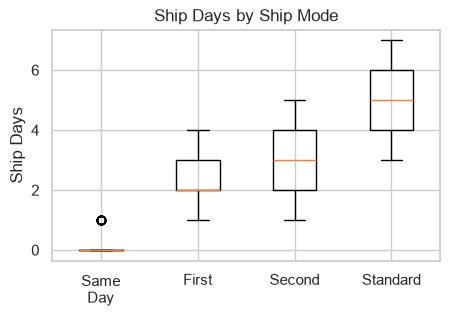

In [212]:
modes=["Same Day","First Class","Second Class","Standard Class"]
data=[dfc.loc[dfc["Ship Mode"]==m,"Ship Days"] for m in modes]

plt.figure(figsize=(5,3))
plt.boxplot(data)
plt.xticks([1,2,3,4],["Same\nDay","First","Second","Standard"])
plt.title("Ship Days by Ship Mode")
plt.ylabel("Ship Days")
plt.show()

In [213]:
dfc.groupby("Ship Mode")["Ship Days"].agg(["median","mean","std"]).loc[modes]

,median,mean,std
Ship Mode,,,
Same Day,0.0,0.044199,0.205726
First Class,2.0,2.182705,0.773529
Second Class,3.0,3.238046,1.188245
Standard Class,5.0,5.006535,1.010813


# 11. Scatter Plot: Two Numbers

A scatter plot puts one dot for every row, using two number columns. It is used to see whether two numbers move together.

* `alpha` makes the dots see-through, so overlapping dots show where the data is crowded
* `s` is the size of the dots

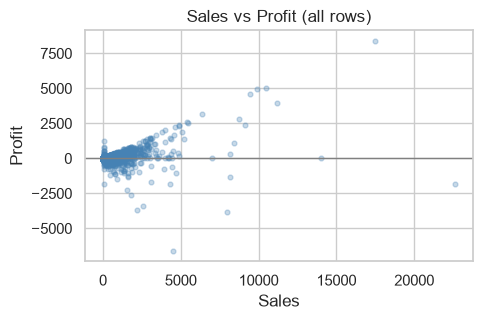

In [214]:
plt.figure(figsize=(5,3))
plt.scatter(dfc["Sales"],dfc["Profit"],alpha=0.3,s=12,color="steelblue")
plt.axhline(0,color="gray",linewidth=1)
plt.title("Sales vs Profit (all rows)")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

In [215]:
dfc.loc[dfc["Sales"].idxmax(),["Order ID","Category","Sales","Profit"]]     # the biggest sale

Order ID    CA-2014-145317
Category        Technology
Sales             22638.48
Profit          -1811.0784
Name: 2697, dtype: object

Bigger sales tend to bring bigger profit. A few huge points squash all other dots. The largest sale made a loss.

### Color and size

Sales under 3000 only (zoom in). Color = Category, bubble size = Quantity. We draw one scatter for every category, so that each gets its own color and a label for the legend.

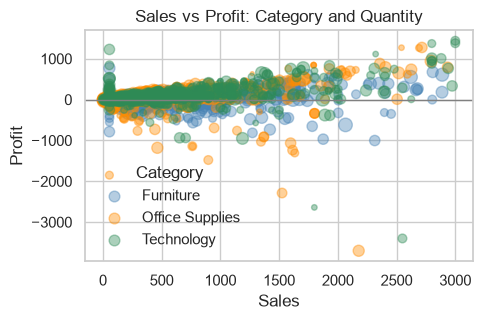

In [216]:
z=dfc[dfc["Sales"]<3000]
colors={"Furniture":"steelblue","Office Supplies":"darkorange","Technology":"seagreen"}

plt.figure(figsize=(5,3))
for c,col in colors.items():
    x=z[z["Category"]==c]
    plt.scatter(x["Sales"],x["Profit"],
                s=x["Quantity"]*8,        # bubble size
                alpha=0.4,color=col,label=c)
plt.axhline(0,color="gray",linewidth=1)
plt.legend(title="Category")
plt.title("Sales vs Profit: Category and Quantity")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

Loss-making rows sit below the grey zero line in every category.

### Trend line and correlation (r)

* `np.polyfit(x,y,1)` finds the best straight line (slope and intercept)
* `x.corr(y)` gives r, between -1 and +1

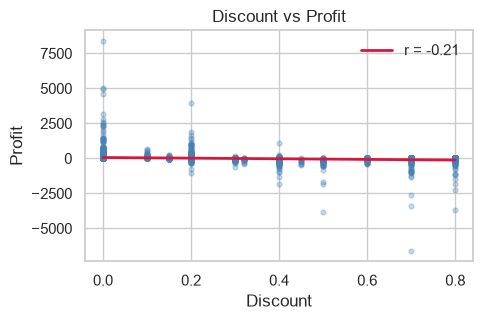

In [217]:
x=dfc["Discount"]
y=dfc["Profit"]
m,b=np.polyfit(x,y,1)          # best straight line : y = m*x + b

plt.figure(figsize=(5,3))
plt.scatter(x,y,alpha=0.3,s=12,color="steelblue")
xs=np.linspace(0,0.8,50)
plt.plot(xs,m*xs+b,color="crimson",linewidth=2,label=f"r = {x.corr(y):.2f}")
plt.legend()
plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

In [218]:
high=dfc[dfc["Discount"]>0.3]
print("Rows with Discount above 0.3 that lose money :",round((high["Profit"]<0).mean()*100),"%")

Rows with Discount above 0.3 that lose money : 89 %


r is negative: a higher discount goes with a lower profit. But r shows a link, not a reason.

### Your Turn: Color by Discount

1. Scatter of Sales (under 3000) vs Profit
2. Color each dot by Discount
3. Add a color bar with a label
4. Where do the yellow dots sit?

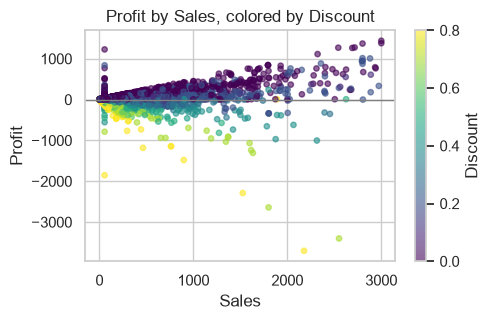

In [219]:
z=dfc[dfc["Sales"]<3000]

plt.figure(figsize=(5,3))
sc=plt.scatter(z["Sales"],z["Profit"],c=z["Discount"],cmap="viridis",alpha=0.6,s=15)
plt.colorbar(sc,label="Discount")        # color key
plt.axhline(0,color="gray",linewidth=1)
plt.title("Profit by Sales, colored by Discount")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

Answer: in viridis the yellow dots are the highest discount. They sit at the bottom, near and below the zero line, so heavy discounts mean small profit or loss.

# 12. Heatmap: A Table in Color

A heatmap colors every cell of a table by its value. In Matplotlib we use `plt.imshow()` and then write the numbers ourselves with `plt.text()`.

A heatmap is readable only with a color bar, labels and numbers in the cells.

In [220]:
t=dfc.pivot_table(index="Region",columns="Category",values="Sales",aggfunc="sum")
t

Category,Furniture,Office Supplies,Technology
Region,,,
Central,156934.3308,165111.955,162189.964
East,204544.8280,204996.035,251713.377
South,103738.5225,124889.089,142356.960
West,242855.1975,218024.104,235190.978


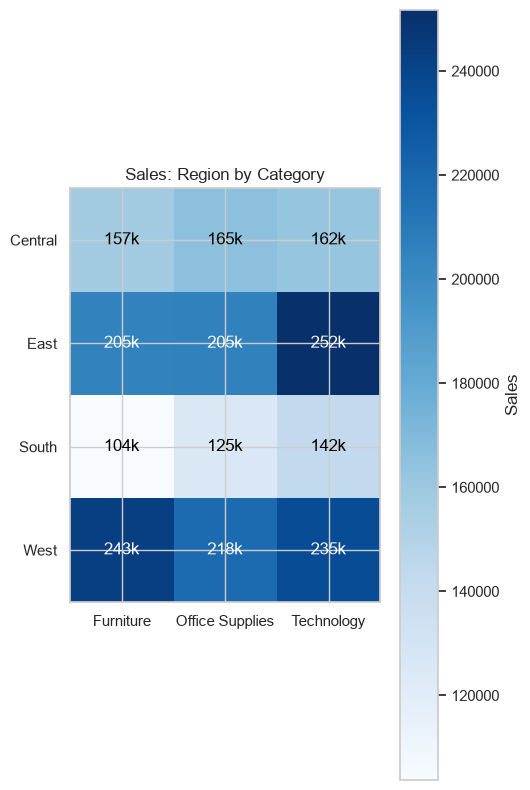

In [221]:
plt.figure(figsize=(5,10))
plt.imshow(t.values,cmap="Blues")
plt.colorbar(label="Sales")
plt.xticks(range(t.shape[1]),t.columns)
plt.yticks(range(t.shape[0]),t.index)
for i in range(t.shape[0]):
    for j in range(t.shape[1]):
        v=t.iloc[i,j]
        txt="white" if v>t.values.mean() else "black"     # white text on dark cells
        plt.text(j,i,f"{v/1000:.0f}k",ha="center",va="center",color=txt)
plt.title("Sales: Region by Category")
plt.show()

Darker = higher sales. East Technology is the top cell. South is the lightest in every category.

### Correlation matrix

`.corr()` gives r for every pair of number columns. `vmin=-1` and `vmax=1` keep the colors fixed for the full range of r.

In [222]:
cm=dfc[["Sales","Quantity","Discount","Profit"]].corr()
cm

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.189788,-0.026931,0.415932
Quantity,0.189788,1.000000,0.008623,0.063669
Discount,-0.026931,0.008623,1.000000,-0.212860
Profit,0.415932,0.063669,-0.212860,1.000000


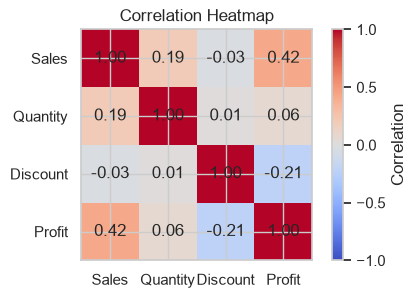

In [223]:
plt.figure(figsize=(5,3))
plt.imshow(cm,cmap="coolwarm",vmin=-1,vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(4),cm.columns)
plt.yticks(range(4),cm.columns)
for i in range(4):
    for j in range(4):
        plt.text(j,i,f"{cm.iloc[i,j]:.2f}",ha="center",va="center")
plt.title("Correlation Heatmap")
plt.show()

Sales and Profit: moderate and positive. Discount and Profit: weak and negative. Quantity is linked to almost nothing.

### Your Turn: Monthly Sales by Year

1. Pivot: MonthNo by Year (Sales, sum)
2. Draw with cmap `YlOrRd` and add a color bar
3. Label the rows Jan to Dec
4. Which cell is the darkest?

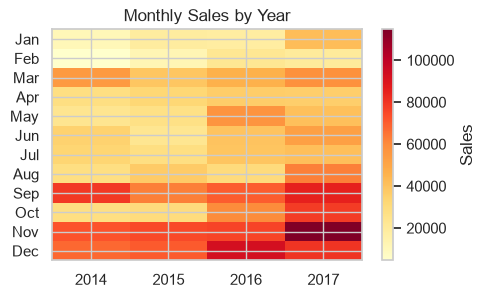

In [224]:
t=dfc.pivot_table(index="MonthNo",columns="Year",values="Sales",aggfunc="sum")
mn=["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

plt.figure(figsize=(5,3))
plt.imshow(t.values,cmap="YlOrRd",aspect="auto")
plt.colorbar(label="Sales")
plt.xticks(range(t.shape[1]),t.columns)
plt.yticks(range(12),mn)
plt.title("Monthly Sales by Year")
plt.show()

In [225]:
darkest=t.stack().idxmax()      # (MonthNo, Year) of the biggest value
print("Darkest cell :",mn[darkest[0]-1],darkest[1],round(t.stack().max()))

Darkest cell : Nov 2017 114644


# 13. Pick the Chart

| Superstore question | Chart |
|---|---|
| How are Discount values spread? | Histogram |
| Share of Sales by Segment | Pie or donut |
| Spread of Profit in each Category, with outliers | Box plot |
| Do bigger discounts mean lower profit? | Scatter plot |
| Sales for every Region and Category at once | Heatmap |
| Orders in each Ship Mode, ranked | Bar chart |

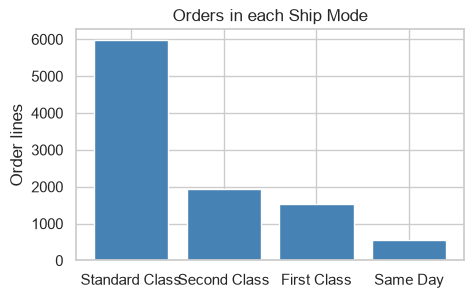

In [226]:
# the last one : orders in each Ship Mode, ranked
sm=dfc["Ship Mode"].value_counts()
plt.figure(figsize=(5,3))
plt.bar(sm.index,sm.values,color="steelblue")
plt.title("Orders in each Ship Mode")
plt.ylabel("Order lines")
plt.show()

# 14. Seaborn: Charts in One Line

Seaborn is built on top of Matplotlib. It gives good looking charts with less code.

* It reads column names straight from the DataFrame: `data=dfc, x="Region", y="Sales"`
* `hue=` splits the chart by color
* `kde=True` adds a smooth curve to a histogram
* `sns.set_theme()` changes the look of all charts
* The same `plt.figure(figsize=(5,3))`, `plt.title()`, `plt.show()` still work, because Seaborn draws with Matplotlib

In [227]:
import seaborn as sns         # pip install seaborn (if not installed)
sns.set_theme(style="whitegrid")

### Line chart

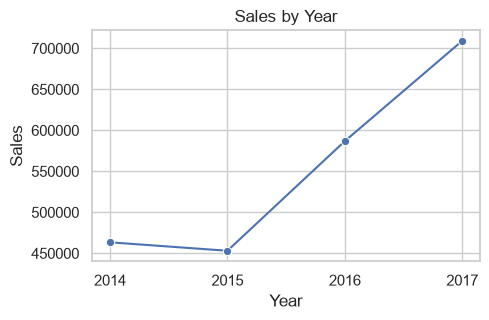

In [228]:
plt.figure(figsize=(5,3))
sns.lineplot(x=yearly.index,y=yearly.values,marker="o")
plt.xticks(yearly.index)
plt.title("Sales by Year")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.show()

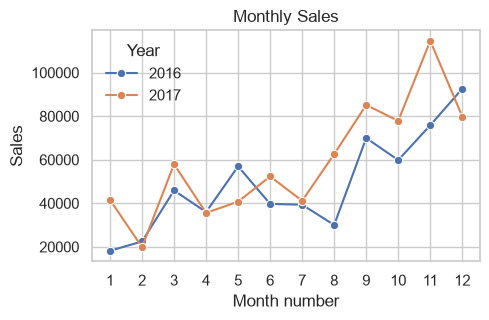

In [229]:
# one line for every year : hue
mon=dfc[dfc["Year"].isin([2016,2017])].groupby(["Year","MonthNo"])["Sales"].sum().reset_index()
mon["Year"]=mon["Year"].astype(str)       # text, so each year gets its own color

plt.figure(figsize=(5,3))
sns.lineplot(data=mon,x="MonthNo",y="Sales",hue="Year",marker="o")
plt.title("Monthly Sales")
plt.xlabel("Month number")
plt.xticks(range(1,13))
plt.show()

### Bar chart

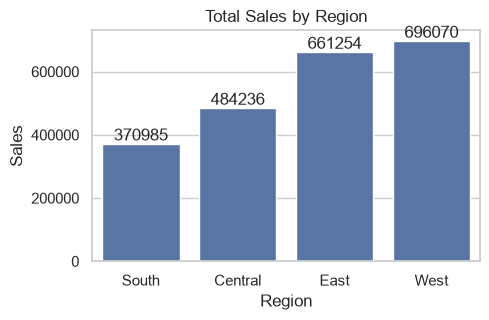

In [230]:
rs=dfc.groupby("Region")["Sales"].sum().sort_values()

plt.figure(figsize=(5,3))
ax=sns.barplot(x=rs.index,y=rs.values)
ax.bar_label(ax.containers[0],fmt="%.0f")
plt.title("Total Sales by Region")
plt.ylabel("Sales")
plt.show()

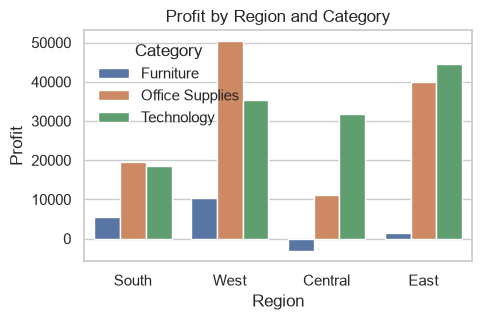

In [231]:
# grouped bars in one line : hue (estimator="sum" because the default is mean)
plt.figure(figsize=(5,3))
sns.barplot(data=dfc,x="Region",y="Profit",hue="Category",estimator="sum",errorbar=None)
plt.title("Profit by Region and Category")
plt.show()

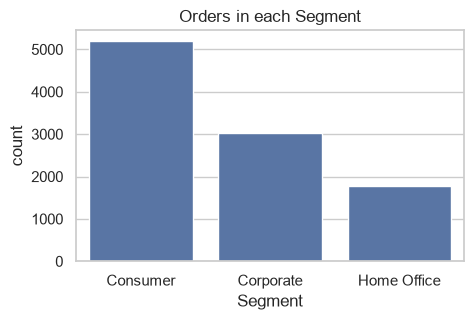

In [232]:
# countplot counts the rows by itself
plt.figure(figsize=(5,3))
sns.countplot(data=dfc,x="Segment")
plt.title("Orders in each Segment")
plt.show()

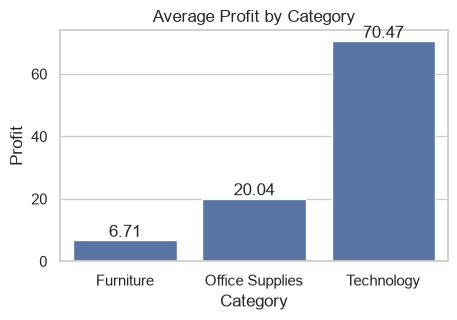

In [233]:
# average profit by category, same as the Your Turn of bar chart
plt.figure(figsize=(5,3))
ax=sns.barplot(data=dfc,x="Category",y="Profit",estimator="mean",errorbar=None,order=ap.index)
ax.bar_label(ax.containers[0],fmt="%.2f")
plt.title("Average Profit by Category")
plt.show()

### Histogram

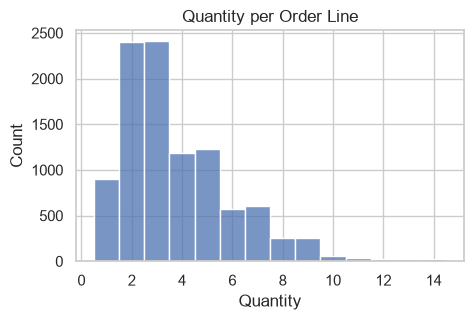

In [234]:
plt.figure(figsize=(5,3))
sns.histplot(dfc["Quantity"],discrete=True)       # discrete=True gives one bar for each value
plt.title("Quantity per Order Line")
plt.show()

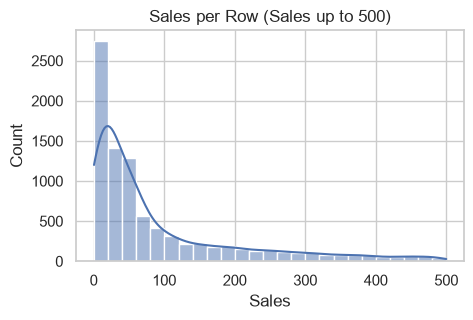

In [235]:
plt.figure(figsize=(5,3))
sns.histplot(s,bins=25,kde=True)                  # kde=True adds the smooth curve
plt.title("Sales per Row (Sales up to 500)")
plt.show()

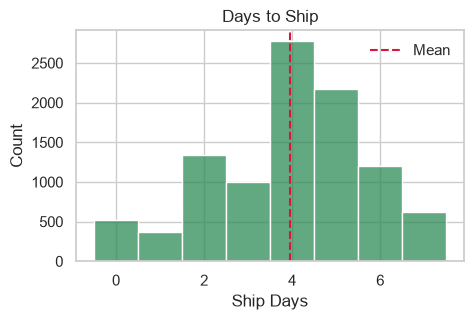

In [236]:
plt.figure(figsize=(5,3))
sns.histplot(dfc["Ship Days"],discrete=True,color="seagreen")
plt.axvline(dfc["Ship Days"].mean(),color="crimson",linestyle="--",label="Mean")
plt.legend()
plt.title("Days to Ship")
plt.show()

### Pie chart

Seaborn has no pie chart. We use `plt.pie()` and take the colors from a Seaborn palette. `"colorblind"` is a palette that color-blind people can read.

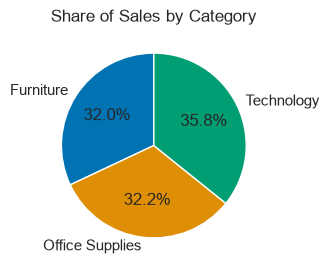

In [237]:
plt.figure(figsize=(5,3))
plt.pie(cs.values,labels=cs.index,autopct="%1.1f%%",startangle=90,
        colors=sns.color_palette("colorblind"))
plt.title("Share of Sales by Category")
plt.show()

### Box plot

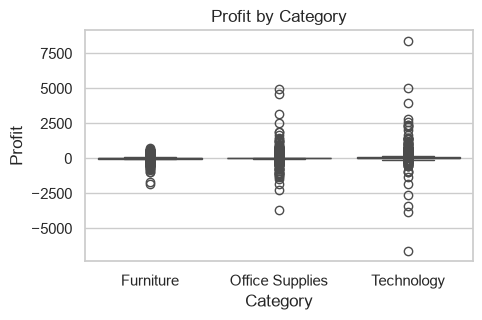

In [238]:
plt.figure(figsize=(5,3))
sns.boxplot(data=dfc,x="Category",y="Profit")
plt.title("Profit by Category")
plt.show()

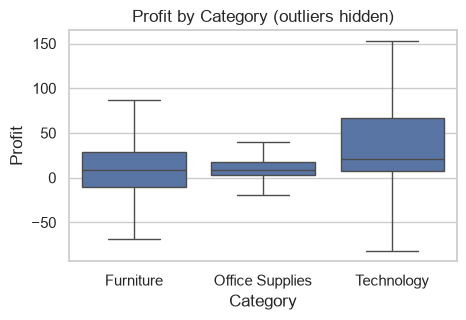

In [239]:
plt.figure(figsize=(5,3))
sns.boxplot(data=dfc,x="Category",y="Profit",showfliers=False)
plt.title("Profit by Category (outliers hidden)")
plt.show()

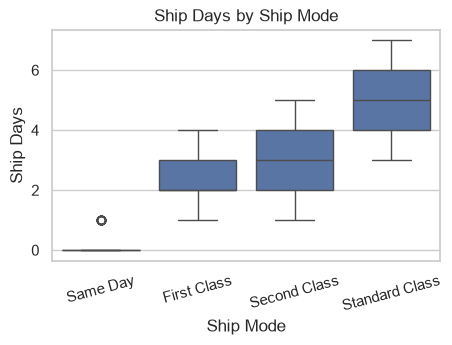

In [240]:
plt.figure(figsize=(5,3))
sns.boxplot(data=dfc,x="Ship Mode",y="Ship Days",order=modes)
plt.title("Ship Days by Ship Mode")
plt.xticks(rotation=15)
plt.show()

### Violin plot

A violin plot is a box plot plus the shape of the data. The wide part means many rows there, and the white dot is the median. Same Day is flat at 0 and Standard Class is widest near 5 days.

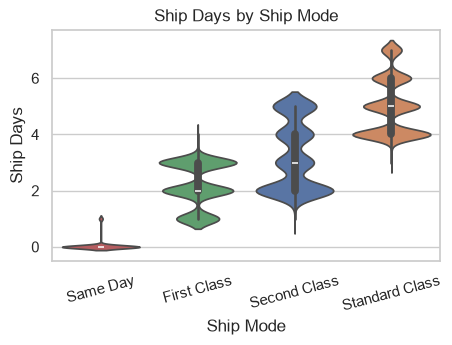

In [241]:
plt.figure(figsize=(5,3))
sns.violinplot(data=dfc,x="Ship Mode",y="Ship Days",order=modes,
               hue="Ship Mode",legend=False)
plt.title("Ship Days by Ship Mode")
plt.xticks(rotation=15)
plt.show()

### Scatter plot

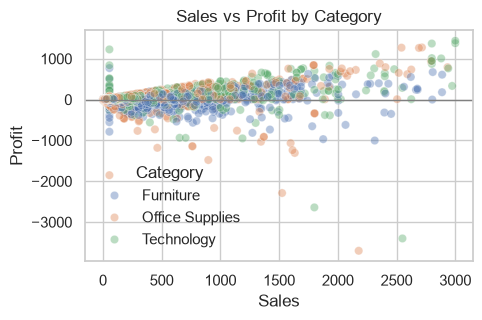

In [242]:
z=dfc[dfc["Sales"]<3000]

plt.figure(figsize=(5,3))
sns.scatterplot(data=z,x="Sales",y="Profit",hue="Category",alpha=0.4)    # hue gives the color
plt.axhline(0,color="gray",linewidth=1)
plt.title("Sales vs Profit by Category")
plt.show()
# size="Quantity" can be added in the same way to get bubbles

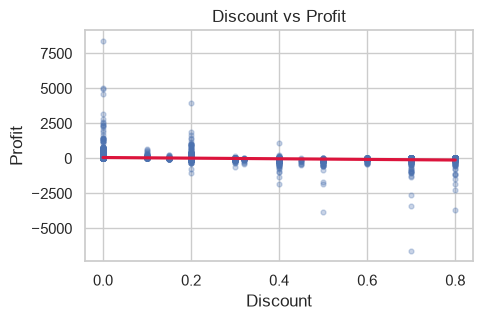

In [243]:
# regplot draws the dots and the trend line together
plt.figure(figsize=(5,3))
sns.regplot(data=dfc,x="Discount",y="Profit",
            scatter_kws={"alpha":0.3,"s":12},line_kws={"color":"crimson"})
plt.title("Discount vs Profit")
plt.show()

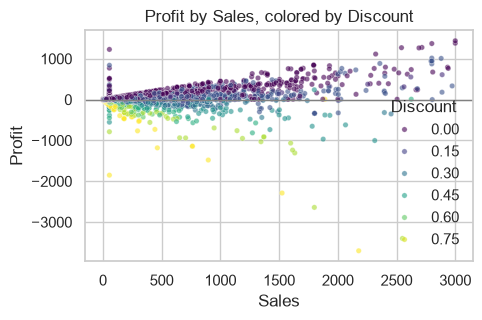

In [244]:
plt.figure(figsize=(5,3))
sns.scatterplot(data=z,x="Sales",y="Profit",hue="Discount",palette="viridis",alpha=0.6,s=15)
plt.axhline(0,color="gray",linewidth=1)
plt.title("Profit by Sales, colored by Discount")
plt.show()

### Heatmap

`sns.heatmap()` does everything we did by hand with `imshow`: the color bar, the labels and the numbers (`annot=True`).

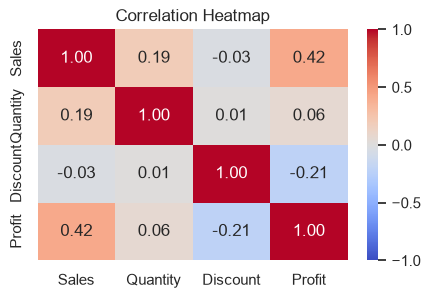

In [245]:
plt.figure(figsize=(5,3))
sns.heatmap(cm,annot=True,fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1)
plt.title("Correlation Heatmap")
plt.show()

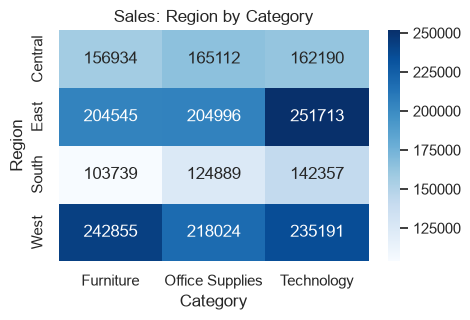

In [246]:
t=dfc.pivot_table(index="Region",columns="Category",values="Sales",aggfunc="sum")

plt.figure(figsize=(5,3))
sns.heatmap(t,annot=True,fmt=".0f",cmap="Blues")
plt.title("Sales: Region by Category")
plt.show()

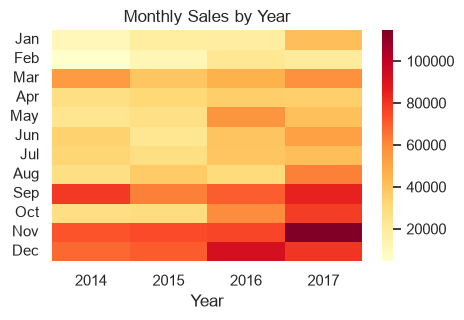

In [247]:
t=dfc.pivot_table(index="MonthNo",columns="Year",values="Sales",aggfunc="sum")
t.index=mn        # month names as row labels

plt.figure(figsize=(5,3))
sns.heatmap(t,cmap="YlOrRd")
plt.title("Monthly Sales by Year")
plt.show()

### Pair plot

Every pair of number columns in one go. The diagonal shows the spread of each column, and `hue=` colors the dots by Category. A pair plot makes its own figure, so the size is set with `height` (the size of one small chart) and not with `figsize`.

We take a small sample, because thousands of dots make it slow and unreadable.

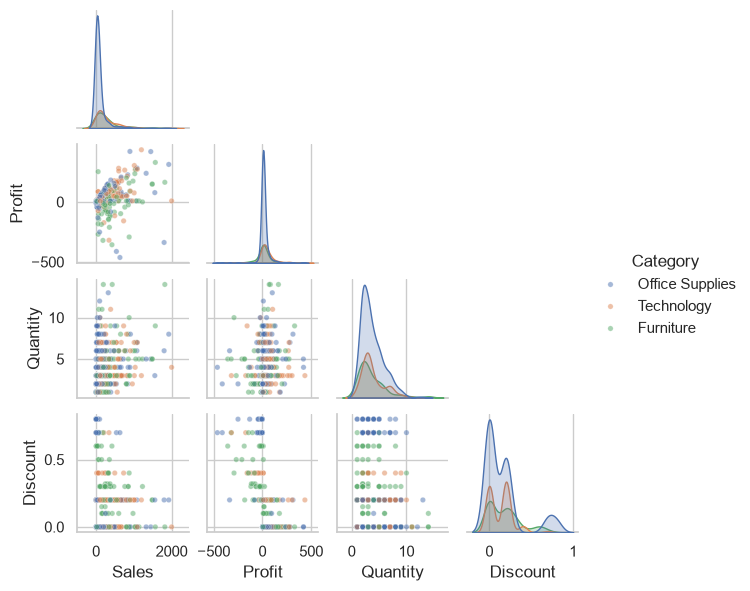

In [248]:
cols=["Sales","Profit","Quantity","Discount","Category"]
small=dfc[(dfc["Sales"]<2000)&dfc["Profit"].between(-500,500)].sample(800,random_state=1)

sns.pairplot(small[cols],hue="Category",corner=True,height=1.5,
             plot_kws={"alpha":0.5,"s":15})
plt.show()

### Themes and color palettes

* `sns.set_theme(style="...")` : darkgrid, whitegrid, dark, white, ticks
* `sns.color_palette("colorblind")` : colors that everybody can read
* Other palettes: `"deep"`, `"pastel"`, `"Set2"`

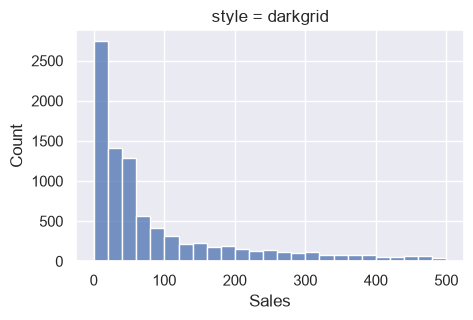

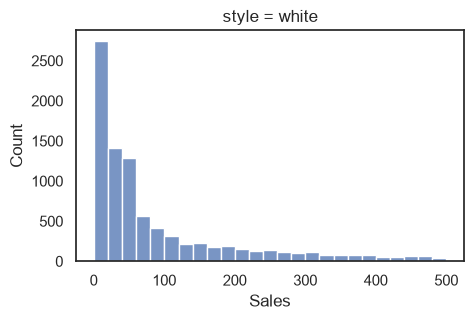

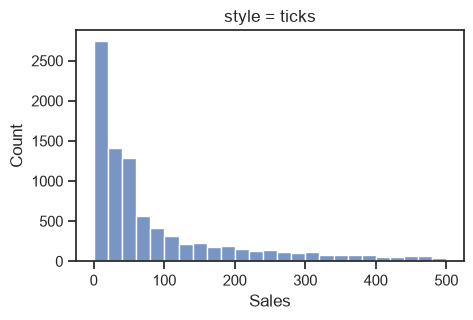

In [249]:
for st in ["darkgrid","white","ticks"]:
    sns.set_theme(style=st)
    plt.figure(figsize=(5,3))
    sns.histplot(s,bins=25)
    plt.title(f"style = {st}")
    plt.show()

sns.set_theme(style="whitegrid")     # back to our normal style

In [250]:
sns.color_palette("colorblind")

[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

# 15. Subplots: A Mini Dashboard

`plt.subplots(2,2)` gives four charts in one image. Every small chart gets about 5 x 3, so the figure is `figsize=(10,6)`.

* `ax[0,0]` is the first row and first column, `ax[0,1]` is the first row and second column...
* `fig.suptitle()` is the title of the whole figure
* `plt.savefig()` before `plt.show()`, and `dpi=300` for print quality

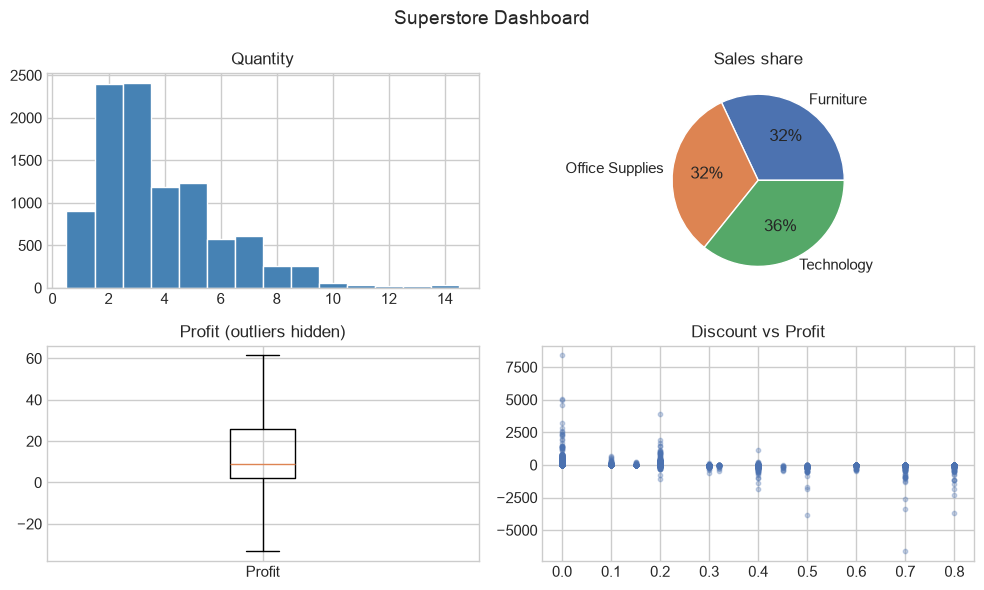

In [251]:
plt.style.use("seaborn-v0_8-whitegrid")
cs=dfc.groupby("Category")["Sales"].sum()

fig,ax=plt.subplots(2,2,figsize=(10,6))

ax[0,0].hist(dfc["Quantity"],bins=np.arange(0.5,15.5),color="steelblue")
ax[0,0].set_title("Quantity")

ax[0,1].pie(cs.values,labels=cs.index,autopct="%1.0f%%")
ax[0,1].set_title("Sales share")

ax[1,0].boxplot(dfc["Profit"],showfliers=False)
ax[1,0].set_xticks([1])
ax[1,0].set_xticklabels(["Profit"])
ax[1,0].set_title("Profit (outliers hidden)")

ax[1,1].scatter(dfc["Discount"],dfc["Profit"],alpha=0.3,s=10)
ax[1,1].set_title("Discount vs Profit")

fig.suptitle("Superstore Dashboard",fontsize=14)
plt.tight_layout()
plt.savefig("dashboard.png",dpi=300)      # before show()
plt.show()

# 16. Customizing Plots

| Goal | Code |
|---|---|
| Title and labels | `plt.title()` `plt.xlabel()` `plt.ylabel()` |
| Legend | `label="A"` inside the plot, then `plt.legend(title="...")` |
| Colors | `color="steelblue"` or `cmap="viridis"` |
| Figure size | `plt.figure(figsize=(5,3))` and `s=12` for the size of dots |
| See-through | `alpha=0.3` (fixes overlapping dots) |
| Reference line | `plt.axhline(0)` `plt.axvline(mean)` |
| Text with an arrow | `plt.annotate()` |
| Style or theme | `plt.style.use(...)` `sns.set_theme()` |
| Save an image | `plt.savefig("name.png",dpi=300)` before `plt.show()` |

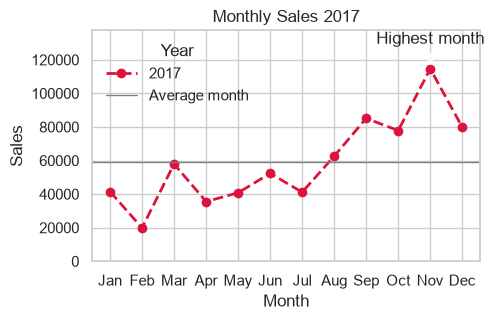

In [252]:
# one chart with many customizations
sns.set_theme(style="whitegrid")
m=dfc[dfc["Year"]==2017].groupby("MonthNo")["Sales"].sum()
top=m.idxmax()

plt.figure(figsize=(5,3))
plt.plot(m.index,m.values,marker="o",color="crimson",linestyle="--",linewidth=2,label="2017")
plt.axhline(m.mean(),color="gray",linewidth=1,label="Average month")
plt.annotate("Highest month",xy=(top,m[top]),xytext=(0,18),textcoords="offset points",
             ha="center",arrowprops={"arrowstyle":"->"})     # text is placed 18 points above the point
plt.ylim(0,m.max()*1.2)         # extra space on top for the text
plt.xticks(range(1,13),mn)
plt.legend(title="Year")
plt.title("Monthly Sales 2017")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.savefig("monthly_2017.png",dpi=300)
plt.show()

# 17. Cheat Sheet: Chart to Code

| Chart | Matplotlib | Seaborn | Use when |
|---|---|---|---|
| Line | `plt.plot(x,y)` | `sns.lineplot()` | Change over time |
| Bar | `plt.bar(x,h)` | `sns.barplot()` | Compare categories |
| Histogram | `plt.hist(x,bins=)` | `sns.histplot(kde=True)` | Spread of one number |
| Pie / donut | `plt.pie(v,labels=)` | - | Share of a whole |
| Box plot | `plt.boxplot(list)` | `sns.boxplot()` | Spread and outliers |
| Violin | - | `sns.violinplot()` | Spread and shape |
| Scatter | `plt.scatter(x,y)` | `sns.scatterplot()` | Two numbers |
| Heatmap | `plt.imshow(m)` | `sns.heatmap(annot=True)` | Many numbers |
| Pair plot | - | `sns.pairplot(hue=)` | All pairs at once |


# Homework (Lab 8 and 9)

Q1. Box plot of Sales by Segment, outliers hidden

Q2. Scatter: Quantity vs Sales, colored by Region

Q3. Heatmap: Sub-Category by Region (Profit, sum)

Q4. Save all three as PNG, dpi=300

Q5. Write one sentence of insight under each chart

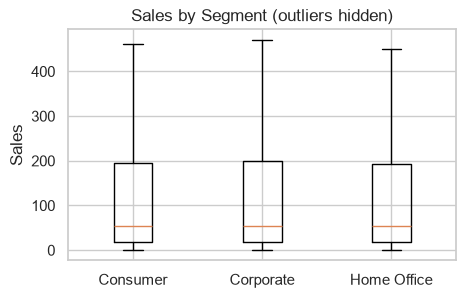

In [253]:
# Q1
segs=["Consumer","Corporate","Home Office"]
data=[dfc.loc[dfc["Segment"]==sg,"Sales"] for sg in segs]

plt.figure(figsize=(5,3))
plt.boxplot(data,showfliers=False)
plt.xticks([1,2,3],segs)
plt.title("Sales by Segment (outliers hidden)")
plt.ylabel("Sales")
plt.savefig("hw_box_sales_segment.png",dpi=300)
plt.show()

In [254]:
print(dfc.groupby("Segment")["Sales"].median())

Segment
Consumer       54.9
Corporate      54.9
Home Office    54.9
Name: Sales, dtype: float64


Insight Q1: (write one sentence here after looking at the chart and the medians)

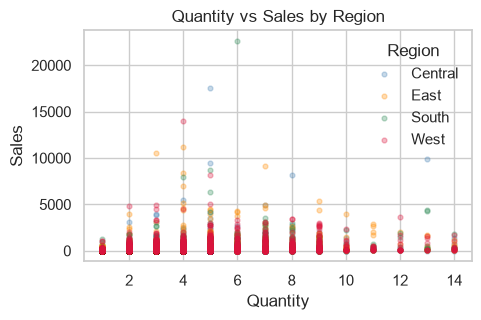

In [255]:
# Q2
colors={"Central":"steelblue","East":"darkorange","South":"seagreen","West":"crimson"}

plt.figure(figsize=(5,3))
for r,col in colors.items():
    x=dfc[dfc["Region"]==r]
    plt.scatter(x["Quantity"],x["Sales"],alpha=0.3,s=12,color=col,label=r)
plt.legend(title="Region")
plt.title("Quantity vs Sales by Region")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.savefig("hw_scatter_quantity_sales.png",dpi=300)
plt.show()

In [256]:
print("r between Quantity and Sales :",round(dfc["Quantity"].corr(dfc["Sales"]),2))

r between Quantity and Sales : 0.19


Insight Q2: (write one sentence here after looking at the chart and r)

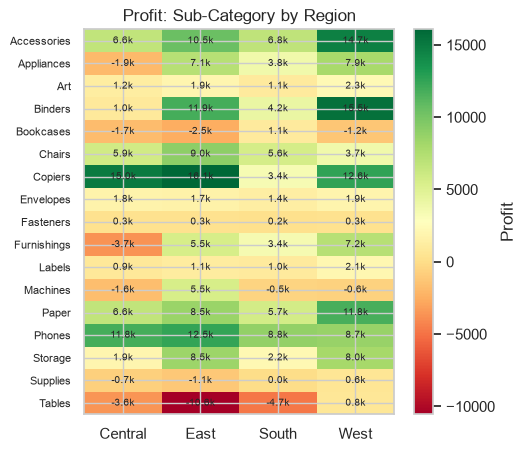

In [257]:
# Q3  17 sub categories need more height, so this is the only chart taller than 5 x 3
t=dfc.pivot_table(index="Sub-Category",columns="Region",values="Profit",aggfunc="sum")

plt.figure(figsize=(5,5))
plt.imshow(t.values,cmap="RdYlGn",aspect="auto")      # red = loss, green = profit
plt.colorbar(label="Profit")
plt.xticks(range(t.shape[1]),t.columns)
plt.yticks(range(t.shape[0]),t.index,fontsize=8)
for i in range(t.shape[0]):
    for j in range(t.shape[1]):
        plt.text(j,i,f"{t.iloc[i,j]/1000:.1f}k",ha="center",va="center",fontsize=7)
plt.title("Profit: Sub-Category by Region")
plt.savefig("hw_heatmap_subcategory_region.png",dpi=300)
plt.show()

In [258]:
best=t.stack().idxmax()
worst=t.stack().idxmin()
print("Highest profit cell :",best,round(t.stack().max()))
print("Lowest profit cell :",worst,round(t.stack().min()))

Highest profit cell : ('Copiers', 'East') 16065
Lowest profit cell : ('Tables', 'East') -10560


Insight Q3: (write one sentence here after looking at the chart and the two cells above)